# Ejercicio 4: ¿Es posible reconstruir la imagen de manera única?

**Etiqueta de uso de IA:** *Asistencia para destrabar / corregir*.

Ya sabemos escribir la adquisición como $b = Ax$ con $A \in \mathbb{R}^{m\times 64}$. La
pregunta ahora es si esas mediciones **alcanzan** para recuperar la imagen. La respuesta es
puramente algebraica y depende del **rango** y del **espacio nulo** de $A$: agregar más
rayos no sirve de nada si las nuevas filas son combinación lineal de las anteriores.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "image.cmap": "gray"})


def guardar(fig, nombre):
    # Guarda la figura en figuras/, como pide el formato de entrega.
    fig.savefig(os.path.join("figuras", nombre + ".png"), bbox_inches="tight", dpi=150)


X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8
x_fantoma = X_fantoma.reshape(-1)   # k = i*n + j


def mascara_rayo(n, direccion, s):
    # M[i,j] = 1  <=>  alpha*i + beta*j == s
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    return (alpha * i + beta * j == s).astype(float)


def matriz_proyeccion(n, direcciones):
    # Devuelve A (m x n^2) y la lista de pares ((alpha, beta), s) de cada fila.
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    filas, info = [], []
    for direccion in direcciones:
        alpha, beta = direccion
        valores_s = np.unique(alpha * i + beta * j)   # np.unique ya devuelve ordenado
        for s in valores_s:
            filas.append(mascara_rayo(n, direccion, int(s)).reshape(-1))
            info.append((direccion, int(s)))
    return np.array(filas, dtype=float), info


## a) Condición de unicidad

Si existe $v \neq 0$ con $Av = 0$, entonces para toda solución $x$ se tiene
$A(x + v) = Ax = b$: dos imágenes distintas dan las mismas mediciones y la reconstrucción no es única. Entonces, la imagen se puede reconstruir de manera única si y sólo si
$\operatorname{Nul}(A) = \{0\}$.

Por el teorema de rango y nulidad, $\operatorname{rango}(A) + \dim(\operatorname{Nul}(A)) = 64,$

así que $\dim(\operatorname{Nul}(A)) = 0$ equivale a $\operatorname{rango}(A) = 64 $.

## Inciso b)

In [2]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

In [3]:
A2, info2 = matriz_proyeccion(n, D2)
A4, info4 = matriz_proyeccion(n, D4)
A7, info7 = matriz_proyeccion(n, D7)

matrices = {2: A2, 4: A4, 7: A7}

filas = []
for k, A in matrices.items():
    m = A.shape[0]
    rango = np.linalg.matrix_rank(A)
    filas.append((k, A.shape, m, rango, 64 - rango, m - rango, rango == 64))

enc = f"{'k':>2} {'dim(A_k)':>12} {'m':>5} {'rango':>6} {'dim Nul':>8} {'m - rango':>10} {'¿única?':>9}"
print(enc)
print("-" * len(enc))
for k, forma, m, rango, nul, red, unica in filas:
    print(f"{k:>2} {str(forma):>12} {m:>5} {rango:>6} {nul:>8} {red:>10} "
          f"{'SÍ' if unica else 'NO':>9}")

 k     dim(A_k)     m  rango  dim Nul  m - rango   ¿única?
----------------------------------------------------------
 2     (16, 64)    16     15       49          1        NO
 4     (46, 64)    46     39       25          7        NO
 7    (119, 64)   119     64        0         55        SÍ


En las tres matrices la cantidad de filas supera al rango, así que todas tienen mediciones redundantes (filas que son combinación lineal de otras).

## Inciso d)

In [9]:
U, S, Vt = np.linalg.svd(A4)
v = Vt[-1]   # vector singular derecho del menor valor singular

print("||v|| (norma) =", np.linalg.norm(v))
print("||A4 v|| (norma) =", np.linalg.norm(A4 @ v))

||v|| (norma) = 0.9999999999999999
||A4 v|| (norma) = 1.1897550721570677e-15


In [10]:
b4 = A4 @ x_fantoma

alfa = 1.0
x_alt = x_fantoma + alfa * v

print("||x_alt - x_fantoma|| =", np.linalg.norm(x_alt - x_fantoma))
print("||A4 x_alt - b4||     =", np.linalg.norm(A4 @ x_alt - b4))

||x_alt - x_fantoma|| = 0.9999999999999999
||A4 x_alt - b4||     = 1.5933321807545196e-15


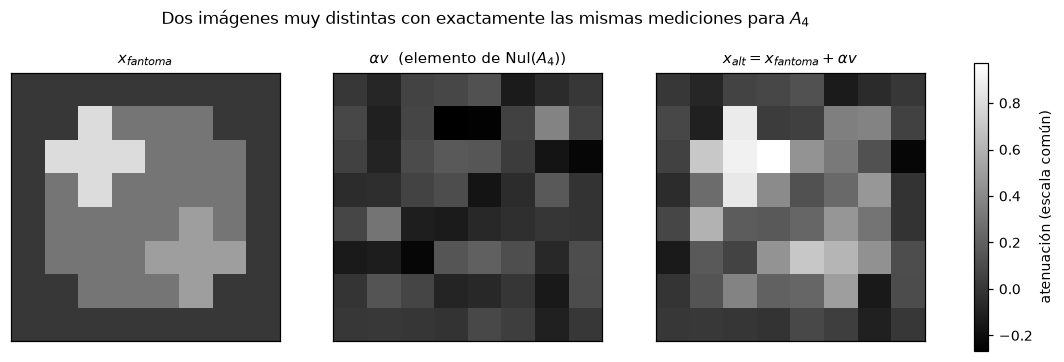

In [12]:
# visualizacion

V_img = (alfa * v).reshape(n, n)
X_alt = x_alt.reshape(n, n)

vmin = min(X_fantoma.min(), X_alt.min(), V_img.min())
vmax = max(X_fantoma.max(), X_alt.max(), V_img.max())

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
titulos = [r"$x_{fantoma}$",
           r"$\alpha v$  (elemento de $\mathrm{Nul}(A_4)$)",
           r"$x_{alt} = x_{fantoma} + \alpha v$"]
for ax, M, t in zip(axes, [X_fantoma, V_img, X_alt], titulos):
    im = ax.imshow(M, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(t, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.018, label="atenuación (escala común)")
fig.suptitle("Dos imágenes muy distintas con exactamente las mismas mediciones para $A_4$",
             y=1.02)
guardar(fig, "ejercicio_04c_espacio_nulo")
plt.show()

La de la izquierda es la imagen original, x_fantoma.

La del medio es el patrón v que sale de la SVD. Es como una atenuación para que la suma de las diagonales, filas y columnas den cero.

La de la derecha es x_alt, la x_fantoma con la SVD integrada.

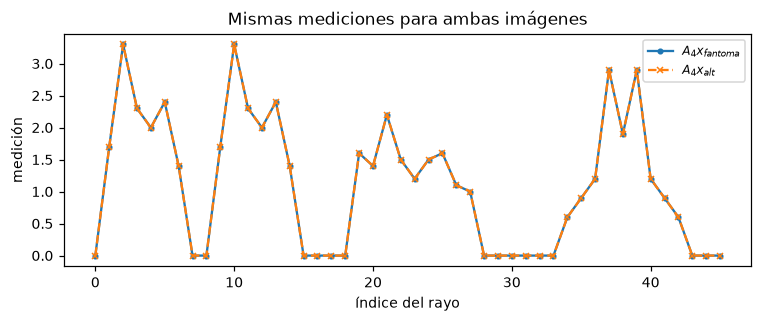

In [13]:
fig, ax = plt.subplots(figsize=(7.0, 3.0))
ax.plot(b4, "o-", ms=3, label=r"$A_4 x_{fantoma}$")
ax.plot(A4 @ x_alt, "x--", ms=4, label=r"$A_4 x_{alt}$")
ax.set_xlabel("índice del rayo")
ax.set_ylabel("medición")
ax.set_title("Mismas mediciones para ambas imágenes")
ax.legend(fontsize=8)
fig.tight_layout()
guardar(fig, "ejercicio_04c_mediciones_iguales")
plt.show()

$A_4$ sólo mide sumas de píxeles a lo largo de filas, columnas y diagonales. Si a la imagen
le sumamos un patrón que suma cero en todas esas líneas, como $v$, ninguna medición cambia.
Esos patrones son los vectores de $\operatorname{Nul}(A_4)$ y el escáner no los puede ver:
por eso $x_{fantoma}$ y $x_{alt}$ son imágenes distintas pero dan las mismas mediciones.